# GoogLeNet / Inception — Going Deeper with Convolutions

**Primary Citation:**
Szegedy, C., Liu, W., Jia, Y., Sermanet, P., Reed, S., Anguelov, D., ... & Rabinovich, A. (2015). Going deeper with convolutions. *CVPR 2015*. arXiv:1409.4842.

**v3 Citation:**
Szegedy, C., Vanhoucke, V., Ioffe, S., Shlens, J., & Wojna, Z. (2016). Rethinking the inception architecture for computer vision. *CVPR 2016*. arXiv:1512.00567.

**Registered names:** `inception_v1`, `inception_v3`

**Summary:** GoogLeNet introduced the Inception module — applying multiple filter sizes (1×1, 3×3, 5×5) in parallel and concatenating results. This multi-scale approach achieved 6.67% top-5 error at ILSVRC 2014 with only 6.8M parameters (vs AlexNet's 60M).

---

| Model | Depth | Params | ILSVRC Top-5 |
|-------|-------|--------|-------------|
| Inception-v1 | 22 | 6.8M | 6.67% |
| Inception-v3 | 48 | 23.8M | 3.58% |

> 📄 **Paper:** Szegedy et al. (2015). Going Deeper with Convolutions. CVPR 2015 · Szegedy et al. (2016). Rethinking the Inception Architecture for Computer Vision. CVPR 2016.
> 🔗 **Link:** <https://arxiv.org/abs/1409.4842>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/inception.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, H, W)"]:::io --> STEM["stem convs + maxpools"]:::stage --> I3["Inception 3a/3b → /8"]:::stage
  I3 --> I4["Inception 4a–4e → /16"]:::stage --> I5["Inception 5a/5b → /32"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph INC["Inception module"]
    direction LR
    X["x"] --> B1["1×1"]:::block
    X --> B2["1×1 → 3×3"]:::block
    X --> B3["1×1 → 5×5 (v3: two 3×3 / factorised n×1, 1×n)"]:::block
    X --> B4["3×3 maxpool → 1×1"]:::block
    B1 & B2 & B3 & B4 --> CAT["concat channels"]:::block
  end
  I3 -.-> INC
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Diagram

```
Input [B, 3, 224, 224]
       │
     Stem (7×7 s2 → MaxPool → 3×3 → MaxPool)
       │  [B, 192, H/8, W/8]
       │
┌──────────────────────────────────────────────────┐
│ Inception Module (parallel branches):           │
│                                                  │
│   ┌──────┐  ┌──────────────┐  ┌───────────────┐  ┌────────────────────┐
│   │ 1×1  │  │ 1×1 → 3×3   │  │ 1×1 → 5×5    │  │ MaxPool → 1×1     │
│   │ Conv │  │ Reduction    │  │ Reduction     │  │ Projection         │
│   └──────┘  └──────────────┘  └───────────────┘  └────────────────────┘
│        └─────────────────┬──────────────────────────────┘
│                          │ Concatenate on channel dim
└──────────────────────────┼──────────────────────────────┘
                           │
       Stage 1: 3a(→256) + 3b(→480) + MaxPool
       Stage 2: 4a..4e (→832) + MaxPool
       Stage 3: 5a(→832) + 5b(→1024) + GlobalAvgPool
                           │
                    pooled_output [B, 1024]
```

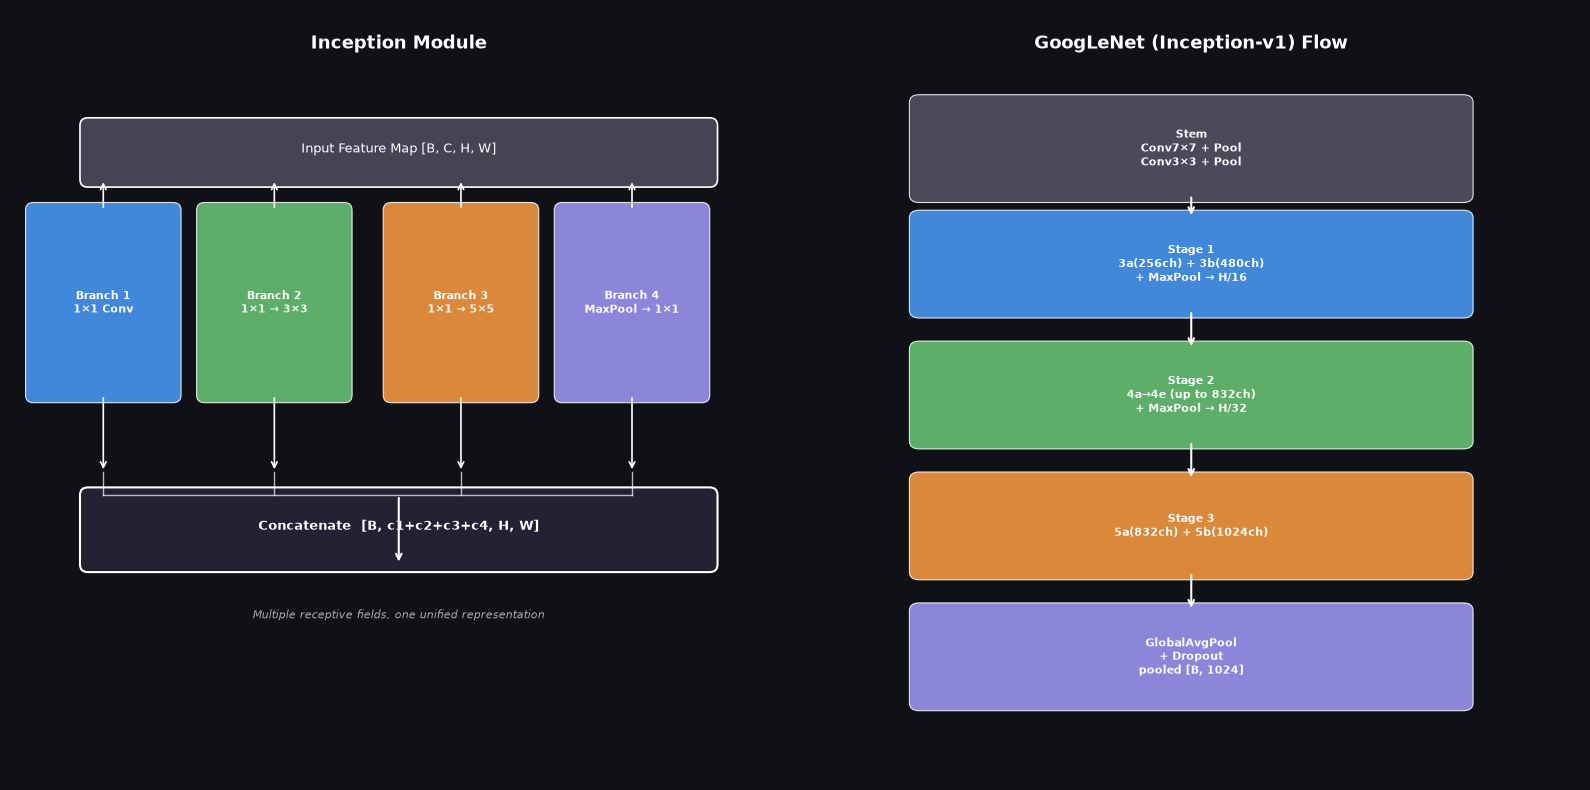

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.patch.set_facecolor('#0f1117')

# ─── Left: Inception Module detail ───
ax = axes[0]
ax.set_facecolor('#0f1117')
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis('off')
ax.text(5, 9.5, 'Inception Module', ha='center', color='white', fontsize=13, fontweight='bold')

branches = [
    ('Branch 1\n1×1 Conv', '#4a9eff', 1.2),
    ('Branch 2\n1×1 → 3×3', '#6bcb77', 3.4),
    ('Branch 3\n1×1 → 5×5', '#ff9f43', 5.8),
    ('Branch 4\nMaxPool → 1×1', '#a29bfe', 8.0),
]

# Input bar
ax.add_patch(FancyBboxPatch((1, 7.8), 8, 0.7, boxstyle='round,pad=0.1',
                             facecolor='#444455', edgecolor='white', linewidth=1.2))
ax.text(5, 8.15, 'Input Feature Map [B, C, H, W]', ha='center', color='white', fontsize=9)

for label, color, cx in branches:
    ax.add_patch(FancyBboxPatch((cx - 0.9, 5.0), 1.8, 2.4,
                                 boxstyle='round,pad=0.1', facecolor=color,
                                 edgecolor='white', linewidth=0.8, alpha=0.85))
    ax.text(cx, 6.2, label, ha='center', va='center', color='white', fontsize=8, fontweight='bold')
    ax.annotate('', xy=(cx, 7.8), xytext=(cx, 7.4),
                arrowprops=dict(arrowstyle='->', color='white', lw=1.2))
    ax.annotate('', xy=(cx, 4.0), xytext=(cx, 5.0),
                arrowprops=dict(arrowstyle='->', color='white', lw=1.2))

# Output concat bar
ax.add_patch(FancyBboxPatch((1, 2.8), 8, 0.9, boxstyle='round,pad=0.1',
                             facecolor='#222233', edgecolor='white', linewidth=1.5))
ax.text(5, 3.25, 'Concatenate  [B, c1+c2+c3+c4, H, W]', ha='center', color='white', fontsize=9, fontweight='bold')

# Connect branches to concat
for _, _, cx in branches:
    ax.plot([cx, cx], [4.0, 3.7], color='white', lw=1, alpha=0.7)
ax.plot([1.2, 8.0], [3.7, 3.7], color='white', lw=1, alpha=0.7)
ax.annotate('', xy=(5, 2.8), xytext=(5, 3.7),
            arrowprops=dict(arrowstyle='->', color='white', lw=1.5))

ax.text(5, 2.1, 'Multiple receptive fields, one unified representation',
        ha='center', color='#aaaaaa', fontsize=8, style='italic')

# ─── Right: GoogLeNet Stage Flow ───
ax2 = axes[1]
ax2.set_facecolor('#0f1117')
ax2.set_xlim(0, 8); ax2.set_ylim(0, 10); ax2.axis('off')
ax2.text(4, 9.5, 'GoogLeNet (Inception-v1) Flow', ha='center', color='white', fontsize=13, fontweight='bold')

flow_blocks = [
    ('Stem\nConv7×7 + Pool\nConv3×3 + Pool', '#555566', 8.2),
    ('Stage 1\n3a(256ch) + 3b(480ch)\n+ MaxPool → H/16', '#4a9eff', 6.7),
    ('Stage 2\n4a→4e (up to 832ch)\n+ MaxPool → H/32', '#6bcb77', 5.0),
    ('Stage 3\n5a(832ch) + 5b(1024ch)', '#ff9f43', 3.3),
    ('GlobalAvgPool\n+ Dropout\npooled [B, 1024]', '#a29bfe', 1.6),
]

for label, color, cy in flow_blocks:
    ax2.add_patch(FancyBboxPatch((1.2, cy - 0.6), 5.6, 1.2,
                                  boxstyle='round,pad=0.1', facecolor=color,
                                  edgecolor='white', linewidth=0.8, alpha=0.85))
    ax2.text(4, cy, label, ha='center', va='center', color='white', fontsize=8, fontweight='bold')

for i in range(len(flow_blocks) - 1):
    y1 = flow_blocks[i][2] - 0.6
    y2 = flow_blocks[i+1][2] + 0.6
    ax2.annotate('', xy=(4, y2), xytext=(4, y1),
                arrowprops=dict(arrowstyle='->', color='white', lw=1.5))

plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. The Inception Module — Multi-Scale Feature Extraction
Instead of choosing a single filter size, the Inception module applies 1×1, 3×3, and 5×5 convolutions in parallel:
$$\text{Inception}(x) = \text{Concat}[W_{1\times1} * x,\ W_{3\times3} * W_r * x,\ W_{5\times5} * W_r' * x,\ \text{MaxPool} * W_p * x]$$

### 2. Dimensionality Reduction with 1×1 Convolutions
Before the 3×3 and 5×5 convolutions, a 1×1 conv reduces the channel count:
$$\text{Cost without reduction: } H \cdot W \cdot C_{in} \cdot k^2 \cdot C_{out}$$
$$\text{Cost with reduction: } H \cdot W \cdot C_{in} \cdot C_r + H \cdot W \cdot C_r \cdot k^2 \cdot C_{out}$$
At $C_r \ll C_{in}$, this gives ~10× parameter reduction for the 5×5 branch.

### 3. Inception-v3: Factorised Convolutions
Any $n \times n$ conv can be approximated by $1 \times n$ followed by $n \times 1$:
$$\text{Params}(n \times n) = n^2 \quad \text{vs} \quad \text{Params}(1 \times n + n \times 1) = 2n$$
For 7×7: saves 49-14=35 parameters per filter, a 28.5% reduction.

### 4. No Large FC Head
GoogLeNet uses Global Average Pooling (not FC layers) to produce the final embedding — eliminating 102M parameters that dominate AlexNet/VGG.

## Code Walkthrough

Implemented in `hale_core/nn/vision/cnn/inception.py`.

**InceptionModuleV1 — the core building block:**
```python
class InceptionModuleV1(nn.Module):
    def __init__(self, in_ch, c1, c2_r, c2, c3_r, c3, c4):
        self.branch1 = ConvBnRelu(in_ch, c1, kernel_size=1)
        self.branch2 = nn.Sequential(
            ConvBnRelu(in_ch, c2_r, kernel_size=1),
            ConvBnRelu(c2_r, c2,   kernel_size=3, padding=1),
        )
        self.branch3 = nn.Sequential(
            ConvBnRelu(in_ch, c3_r, kernel_size=1),
            ConvBnRelu(c3_r, c3,   kernel_size=5, padding=2),
        )
        self.branch4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            ConvBnRelu(in_ch, c4, kernel_size=1),
        )

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch2(x),
                          self.branch3(x), self.branch4(x)], dim=1)
```

**GoogLeNet stage 2 (9 Inception modules including 4a–4e):**
The auxiliary classifiers from the original paper are omitted — they were a training trick to inject gradient early, but modern BN + Adam makes them unnecessary.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/inception.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/inception.py</code></summary>

```text
Inception / GoogLeNet Vision Backbones
=======================================

Implements GoogLeNet / Inception-v1 (Szegedy et al. CVPR 2015) and a clean
modern Inception-v3 (Szegedy et al. CVPR 2016) without auxiliary classifiers.

The key innovation is the Inception module: instead of choosing one filter size,
apply multiple in parallel and concatenate the results.  This captures features
at multiple scales simultaneously within a single layer.

Architecture — GoogLeNet / Inception-v1
-----------------------------------------
  Stem:    Conv(7×7,s2)+BN+ReLU → MaxPool → LRN → Conv(1×1) → Conv(3×3)+BN → MaxPool
  Stage 1: Inception 3a + 3b → MaxPool(3,s2)   → 480 ch, H/16
  Stage 2: Inception 4a–4e   → MaxPool(3,s2)   → 832 ch, H/32
  Stage 3: Inception 5a + 5b → GlobalAvgPool   → [B, 1024]

Architecture — Inception-v3 (clean version, no auxiliary classifiers)
-----------------------------------------------------------------------
  Uses factorised convolutions throughout:
  Type-A: replaces 5×5 with two 3×3
  Type-B: factorises n×n into 1×n + n×1 (asymmetric)
  Type-C: splits 3×3 into 1×3 + 3×1 in parallel (for high-level stages)
  embed_dim=1280.

Registered names
----------------
  inception_v1, inception_v3

Citation
--------
  Szegedy, C., Liu, W., Jia, Y., et al. (2015). Going Deeper with Convolutions.
  CVPR 2015. arXiv:1409.4842.

  Szegedy, C., Vanhoucke, V., Ioffe, S., Shlens, J., & Wojna, Z. (2016).
  Rethinking the Inception Architecture for Computer Vision. CVPR 2016.
  arXiv:1512.00567.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/inception.py`, definition by definition

**`ConvBnRelu`** - Conv2d + BatchNorm2d + ReLU — the atomic unit in all Inception variants.

In [5]:
class ConvBnRelu(nn.Module):
    """Conv2d + BatchNorm2d + ReLU — the atomic unit in all Inception variants."""
    def __init__(self, in_ch: int, out_ch: int, **conv_kwargs) -> None:
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, bias=False, **conv_kwargs)
        self.bn   = nn.BatchNorm2d(out_ch, eps=0.001)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.relu(self.bn(self.conv(x)), inplace=True)

**`InceptionModuleV1`** - Inception module as defined in GoogLeNet (Szegedy et al. 2015).

In [6]:
class InceptionModuleV1(nn.Module):
    """Inception module as defined in GoogLeNet (Szegedy et al. 2015).

    Four parallel branches computed independently then concatenated on the
    channel dimension, capturing features at multiple receptive field sizes.

    Args:
        in_ch: Input channels.
        c1:    Branch-1 output channels (1×1 conv).
        c2_r:  Branch-2 reduction (1×1 before 3×3).
        c2:    Branch-2 output (3×3 conv).
        c3_r:  Branch-3 reduction (1×1 before 5×5).
        c3:    Branch-3 output (5×5 conv).
        c4:    Branch-4 output (1×1 after MaxPool).
    """
    def __init__(
        self,
        in_ch: int,
        c1: int,
        c2_r: int, c2: int,
        c3_r: int, c3: int,
        c4: int,
    ) -> None:
        super().__init__()
        self.branch1 = ConvBnRelu(in_ch, c1, kernel_size=1)
        self.branch2 = nn.Sequential(
            ConvBnRelu(in_ch, c2_r, kernel_size=1),
            ConvBnRelu(c2_r, c2, kernel_size=3, padding=1),
        )
        self.branch3 = nn.Sequential(
            ConvBnRelu(in_ch, c3_r, kernel_size=1),
            ConvBnRelu(c3_r, c3, kernel_size=5, padding=2),
        )
        self.branch4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            ConvBnRelu(in_ch, c4, kernel_size=1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat([self.branch1(x), self.branch2(x), self.branch3(x), self.branch4(x)], dim=1)

**`GoogLeNet`** - GoogLeNet (Inception-v1) backbone.

In [7]:
class GoogLeNet(BaseVisionBackbone):
    """GoogLeNet (Inception-v1) backbone.

    Returns 4-scale feature maps (stem + one per MaxPool boundary) plus a
    1024-dim global pooled embedding from the final Inception stage.
    """

    arch_name    = "inception_v1"
    embed_dim    = 1024
    feature_dims = [192, 480, 832, 1024]

    def __init__(
        self,
        img_size:  int   = 224,
        in_chans:  int   = 3,
        drop_rate: float = 0.0,
        **kwargs,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate)

        # Stem: aggressive spatial reduction before Inception modules begin
        self.stem = nn.Sequential(
            ConvBnRelu(in_chans, 64, kernel_size=7, stride=2, padding=3),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            ConvBnRelu(64, 64, kernel_size=1),
            ConvBnRelu(64, 192, kernel_size=3, padding=1),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )  # → [B, 192, H/8, W/8]

        # Stage 1: Inception 3a (256 ch) + 3b (480 ch) → MaxPool → [B, 480, H/16]
        self.stage1 = nn.Sequential(
            InceptionModuleV1(192, 64,  96, 128, 16,  32, 32),   # 3a → 256
            InceptionModuleV1(256, 128, 128, 192, 32,  96, 64),  # 3b → 480
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # Stage 2: Inception 4a–4e (up to 832 ch) → MaxPool → [B, 832, H/32]
        self.stage2 = nn.Sequential(
            InceptionModuleV1(480, 192,  96, 208, 16,  48, 64),  # 4a → 512
            InceptionModuleV1(512, 160, 112, 224, 24,  64, 64),  # 4b → 512
            InceptionModuleV1(512, 128, 128, 256, 24,  64, 64),  # 4c → 512
            InceptionModuleV1(512, 112, 144, 288, 32,  64, 64),  # 4d → 528
            InceptionModuleV1(528, 256, 160, 320, 32, 128, 128), # 4e → 832
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # Stage 3: Inception 5a (832 ch) + 5b (1024 ch) → GlobalAvgPool
        self.stage3 = nn.Sequential(
            InceptionModuleV1(832, 256, 160, 320, 32, 128, 128),  # 5a → 832
            InceptionModuleV1(832, 384, 192, 384, 48, 128, 128),  # 5b → 1024
        )

        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        s0 = self.stem(x)        # [B, 192, H/8, W/8]
        s1 = self.stage1(s0)     # [B, 480, H/16, W/16]
        s2 = self.stage2(s1)     # [B, 832, H/32, W/32]
        s3 = self.stage3(s2)     # [B, 1024, H/32, W/32]

        pooled = self.dropout(self.pool(s3).flatten(1))  # [B, 1024]

        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        stages = [self.stem, self.stage1, self.stage2, self.stage3]
        for i in range(stage + 1):
            for p in stages[i].parameters():
                p.requires_grad_(False)

**`_ReductionA`** - Grid reduction A: 288 → 768 channels with stride 2.

In [8]:
class _ReductionA(nn.Module):
    """Grid reduction A: 288 → 768 channels with stride 2."""
    def __init__(self, in_ch: int = 288) -> None:
        super().__init__()
        # Branch 1: 3×3 stride-2 conv
        self.br1 = ConvBnRelu(in_ch, 384, kernel_size=3, stride=2)
        # Branch 2: 1×1 → 3×3 → 3×3 stride-2
        self.br2 = nn.Sequential(
            ConvBnRelu(in_ch, 64, kernel_size=1),
            ConvBnRelu(64, 96, kernel_size=3, padding=1),
            ConvBnRelu(96, 96, kernel_size=3, stride=2),
        )
        # Branch 3: MaxPool stride-2 (keeps in_ch channels)
        self.br3 = nn.MaxPool2d(kernel_size=3, stride=2)
        # Total: 384 + 96 + 288 = 768

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat([self.br1(x), self.br2(x), self.br3(x)], dim=1)

**`_ReductionB`** - Grid reduction B: 768 → 1280 channels with stride 2.

In [9]:
class _ReductionB(nn.Module):
    """Grid reduction B: 768 → 1280 channels with stride 2."""
    def __init__(self, in_ch: int = 768) -> None:
        super().__init__()
        self.br1 = nn.Sequential(
            ConvBnRelu(in_ch, 192, kernel_size=1),
            ConvBnRelu(192, 320, kernel_size=3, stride=2),
        )
        self.br2 = nn.Sequential(
            ConvBnRelu(in_ch, 192, kernel_size=1),
            ConvBnRelu(192, 192, kernel_size=(1, 7), padding=(0, 3)),
            ConvBnRelu(192, 192, kernel_size=(7, 1), padding=(3, 0)),
            ConvBnRelu(192, 192, kernel_size=3, stride=2),
        )
        self.br3 = nn.MaxPool2d(kernel_size=3, stride=2)
        # Total: 320 + 192 + 768 = 1280

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat([self.br1(x), self.br2(x), self.br3(x)], dim=1)

**`_InceptionTypeA`** - Inception-v3 Type-A: replaces 5×5 with two 3×3 convs.

In [10]:
class _InceptionTypeA(nn.Module):
    """Inception-v3 Type-A: replaces 5×5 with two 3×3 convs."""
    def __init__(self, in_ch: int, pool_features: int) -> None:
        super().__init__()
        self.br1 = ConvBnRelu(in_ch, 64, kernel_size=1)
        self.br2 = nn.Sequential(
            ConvBnRelu(in_ch, 48, kernel_size=1),
            ConvBnRelu(48, 64, kernel_size=5, padding=2),
        )
        self.br3 = nn.Sequential(
            ConvBnRelu(in_ch, 64, kernel_size=1),
            ConvBnRelu(64, 96, kernel_size=3, padding=1),
            ConvBnRelu(96, 96, kernel_size=3, padding=1),
        )
        self.br4 = nn.Sequential(
            nn.AvgPool2d(kernel_size=3, stride=1, padding=1),
            ConvBnRelu(in_ch, pool_features, kernel_size=1),
        )
        # Total: 64+64+96+pool_features

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat([self.br1(x), self.br2(x), self.br3(x), self.br4(x)], dim=1)

**`_InceptionTypeB`** - Inception-v3 Type-B: factorised n×n → 1×n + n×1 (asymmetric).

In [11]:
class _InceptionTypeB(nn.Module):
    """Inception-v3 Type-B: factorised n×n → 1×n + n×1 (asymmetric)."""
    def __init__(self, in_ch: int, channels_7x7: int) -> None:
        super().__init__()
        c7 = channels_7x7
        self.br1 = ConvBnRelu(in_ch, 192, kernel_size=1)
        self.br2 = nn.Sequential(
            ConvBnRelu(in_ch, c7, kernel_size=1),
            ConvBnRelu(c7, c7, kernel_size=(1, 7), padding=(0, 3)),
            ConvBnRelu(c7, 192, kernel_size=(7, 1), padding=(3, 0)),
        )
        self.br3 = nn.Sequential(
            ConvBnRelu(in_ch, c7, kernel_size=1),
            ConvBnRelu(c7, c7, kernel_size=(7, 1), padding=(3, 0)),
            ConvBnRelu(c7, c7, kernel_size=(1, 7), padding=(0, 3)),
            ConvBnRelu(c7, c7, kernel_size=(7, 1), padding=(3, 0)),
            ConvBnRelu(c7, 192, kernel_size=(1, 7), padding=(0, 3)),
        )
        self.br4 = nn.Sequential(
            nn.AvgPool2d(kernel_size=3, stride=1, padding=1),
            ConvBnRelu(in_ch, 192, kernel_size=1),
        )
        # Total: 192 * 4 = 768

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat([self.br1(x), self.br2(x), self.br3(x), self.br4(x)], dim=1)

**`_InceptionTypeC`** - Inception-v3 Type-C: splits 3×3 into 1×3 + 3×1 in parallel (wide).

In [12]:
class _InceptionTypeC(nn.Module):
    """Inception-v3 Type-C: splits 3×3 into 1×3 + 3×1 in parallel (wide).
    Used in deepest stage for maximum filter bank diversity."""
    def __init__(self, in_ch: int) -> None:
        super().__init__()
        self.br1 = ConvBnRelu(in_ch, 320, kernel_size=1)
        self.br2_r   = ConvBnRelu(in_ch, 384, kernel_size=1)
        self.br2_1x3 = ConvBnRelu(384, 384, kernel_size=(1, 3), padding=(0, 1))
        self.br2_3x1 = ConvBnRelu(384, 384, kernel_size=(3, 1), padding=(1, 0))
        self.br3_r   = ConvBnRelu(in_ch, 448, kernel_size=1)
        self.br3_3x3 = ConvBnRelu(448, 384, kernel_size=3, padding=1)
        self.br3_1x3 = ConvBnRelu(384, 384, kernel_size=(1, 3), padding=(0, 1))
        self.br3_3x1 = ConvBnRelu(384, 384, kernel_size=(3, 1), padding=(1, 0))
        self.br4 = nn.Sequential(
            nn.AvgPool2d(kernel_size=3, stride=1, padding=1),
            ConvBnRelu(in_ch, 192, kernel_size=1),
        )
        # Total: 320 + 384+384 + 384+384 + 192 = 2048

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b1   = self.br1(x)
        b2_r = self.br2_r(x)
        b2   = torch.cat([self.br2_1x3(b2_r), self.br2_3x1(b2_r)], dim=1)  # 768
        b3_r = self.br3_3x3(self.br3_r(x))
        b3   = torch.cat([self.br3_1x3(b3_r), self.br3_3x1(b3_r)], dim=1)  # 768
        b4   = self.br4(x)
        return torch.cat([b1, b2, b3, b4], dim=1)  # 320+768+768+192 = 2048

**`InceptionV3`** - Inception-v3 backbone (no auxiliary classifiers).

In [13]:
class InceptionV3(BaseVisionBackbone):
    """Inception-v3 backbone (no auxiliary classifiers).

    Factorised convolutions throughout; embed_dim=2048 from mixed_7c.
    """

    arch_name    = "inception_v3"
    embed_dim    = 2048
    feature_dims = [192, 768, 1280, 2048]

    def __init__(
        self,
        img_size:  int   = 299,
        in_chans:  int   = 3,
        drop_rate: float = 0.0,
        **kwargs,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate)

        # Stem: 5-step conv sequence → [B, 192, H/8, W/8] approx
        self.stem = nn.Sequential(
            ConvBnRelu(in_chans, 32, kernel_size=3, stride=2),
            ConvBnRelu(32, 32, kernel_size=3),
            ConvBnRelu(32, 64, kernel_size=3, padding=1),
            nn.MaxPool2d(kernel_size=3, stride=2),
            ConvBnRelu(64, 80, kernel_size=1),
            ConvBnRelu(80, 192, kernel_size=3),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # Stage 1 — Type-A × 3: 192 → 256 → 288 → 288
        # _InceptionTypeA outputs 64+64+96+pool = 64+64+96+32 = 256 (pool=32)
        # and 64+64+96+64 = 288 (pool=64)
        self.stage1 = nn.Sequential(
            _InceptionTypeA(192, pool_features=32),   # → 256
            _InceptionTypeA(256, pool_features=64),   # → 288
            _InceptionTypeA(288, pool_features=64),   # → 288
        )

        # Reduction A: 288 → 768
        self.reduction_a = _ReductionA(in_ch=288)

        # Stage 2 — Type-B × 4: 768 → 768 (channels fixed at 192*4=768)
        self.stage2 = nn.Sequential(
            _InceptionTypeB(768, channels_7x7=128),  # → 768
            _InceptionTypeB(768, channels_7x7=160),  # → 768
            _InceptionTypeB(768, channels_7x7=160),  # → 768
            _InceptionTypeB(768, channels_7x7=192),  # → 768
        )

        # Reduction B: 768 → 1280
        self.reduction_b = _ReductionB(in_ch=768)

        # Stage 3 — Type-C × 2: 1280 → 2048 → 2048
        self.stage3 = nn.Sequential(
            _InceptionTypeC(in_ch=1280),  # → 2048
            _InceptionTypeC(in_ch=2048), # → 2048
        )

        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        s0 = self.stem(x)            # [B, 192, ~H/32, ~W/32]
        s1 = self.reduction_a(self.stage1(s0))   # [B, 768, ...]
        s2 = self.reduction_b(self.stage2(s1))   # [B, 1280, ...]
        s3 = self.stage3(s2)         # [B, 2048, ...]

        pooled = self.dropout(self.pool(s3).flatten(1))  # [B, 2048]

        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        stages = [self.stem, self.stage1, self.stage2, self.stage3]
        for i in range(stage + 1):
            for p in stages[i].parameters():
                p.requires_grad_(False)

**`InceptionV1Backbone`** - GoogLeNet / Inception-v1: 22 layers, embed_dim=1024.

In [14]:
@register_vision_backbone("inception_v1")
class InceptionV1Backbone(GoogLeNet):
    """GoogLeNet / Inception-v1: 22 layers, embed_dim=1024."""
    arch_name = "inception_v1"
    def __init__(self, **kwargs): super().__init__(**kwargs)

**`InceptionV3Backbone`** - Inception-v3: factorised convolutions, embed_dim=2048.

In [15]:
@register_vision_backbone("inception_v3")
class InceptionV3Backbone(InceptionV3):
    """Inception-v3: factorised convolutions, embed_dim=2048."""
    arch_name = "inception_v3"
    def __init__(self, **kwargs): super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [16]:
DEMOS = {"inception_v1": 6.6, "inception_v3": 23.8}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['inception_v1', 'inception_v3']

inception_v1  (InceptionV1Backbone)
  pooled_output : (2, 1024)   embed_dim = 1024
  feature_map 0: (2, 192, 28, 28)   stride 8
  feature_map 1: (2, 480, 14, 14)   stride 16
  feature_map 2: (2, 832, 7, 7)   stride 32
  feature_map 3: (2, 1024, 7, 7)   stride 32



inception_v3  (InceptionV3Backbone)
  pooled_output : (2, 2048)   embed_dim = 2048
  feature_map 0: (2, 192, 25, 25)   stride 9
  feature_map 1: (2, 768, 12, 12)   stride 19
  feature_map 2: (2, 1280, 5, 5)   stride 45
  feature_map 3: (2, 2048, 5, 5)   stride 45


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [17]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
inception_v1              5.98M      7.01M     6.6M    1.06  ⚠️ differs from paper
inception_v3             21.79M     23.83M    23.8M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [18]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

inception_v1: loss 7.4352 | 171/171 parameter tensors receive a finite gradient
inception_v3: loss 5.7855 | 282/282 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [19]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

inception_v1: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


inception_v3: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

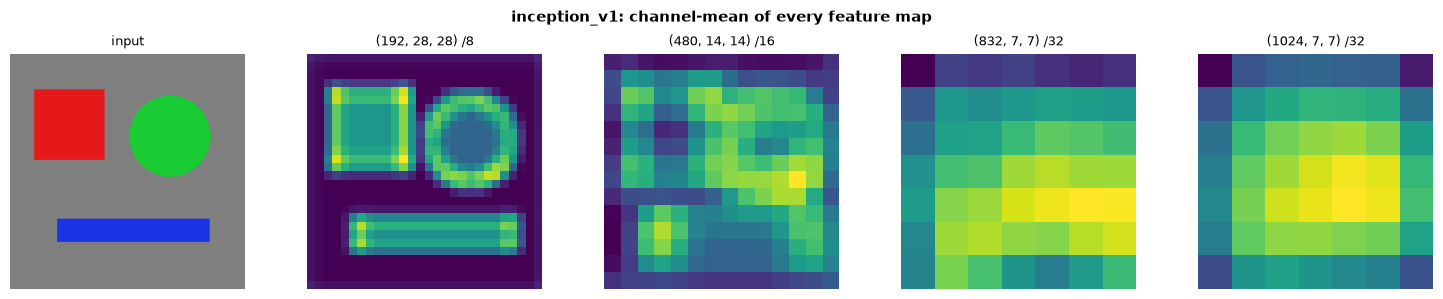

In [20]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [21]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [22]:
import torch
import sys


for name, size in [('inception_v1', 224), ('inception_v3', 299)]:
    bb = build_vision_backbone(name, img_size=size)
    bb.eval()
    x = torch.randn(1, 3, size, size)
    with torch.no_grad():
        out = bb(x)
    print(f'{name} (input {size}×{size}):')
    print(f'  pooled_output: {tuple(out.pooled_output.shape)}')
    print(f'  feature_maps:  {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params: {bb.num_parameters()/1e6:.1f}M')

inception_v1 (input 224×224):
  pooled_output: (1, 1024)
  feature_maps:  [(1, 192, 28, 28), (1, 480, 14, 14), (1, 832, 7, 7), (1, 1024, 7, 7)]
  params: 6.0M


inception_v3 (input 299×299):
  pooled_output: (1, 2048)
  feature_maps:  [(1, 192, 35, 35), (1, 768, 17, 17), (1, 1280, 8, 8), (1, 2048, 8, 8)]
  params: 21.8M


## References

| Paper | Venue | Key Contribution |
|-------|-------|------------------|
| Szegedy et al. (2015). Going Deeper with Convolutions. | CVPR 2015 | Inception-v1 / GoogLeNet — parallel multi-scale branches |
| Szegedy et al. (2016). Rethinking the Inception Architecture. | CVPR 2016 | Inception-v3 — factorised convolutions |
| Szegedy et al. (2017). Inception-v4, Inception-ResNet. | AAAI 2017 | Inception + residual connections |
| Lin et al. (2014). Network in Network. | ICLR 2014 | 1×1 convolutions as dimensionality reduction |
| Ioffe & Szegedy (2015). Batch Normalisation. | ICML 2015 | Enabled removing auxiliary classifiers |

**Full Citations:**
> Szegedy, C., Liu, W., Jia, Y., Sermanet, P., Reed, S., Anguelov, D., Erhan, D., Vanhoucke, V., & Rabinovich, A. (2015). Going deeper with convolutions. In *Proceedings of CVPR 2015* (pp. 1–9). arXiv:1409.4842.
>
> Szegedy, C., Vanhoucke, V., Ioffe, S., Shlens, J., & Wojna, Z. (2016). Rethinking the inception architecture for computer vision. In *Proceedings of CVPR 2016* (pp. 2818–2826). arXiv:1512.00567.